# Practical 1 — Python for Machine Learning and the ML Workflow

**Lectures:** 1. Introduction · 2. Machine Learning Workflow and Coding Environment

In this practical you will (re)familiarise yourself with the Python scientific stack
(NumPy, pandas, matplotlib, scikit-learn) and walk through **all seven steps of the
machine learning workflow** on a small real dataset:

1. Problem framing → 2. Data preparation → 3. Algorithm selection → 4. Model training →
5. Model testing → 6. Hyperparameter tuning → 7. Inference / prediction

Along the way you will write your **first learning algorithm from scratch** — a
*nearest-centroid* classifier — using the same `fit` / `predict` interface as scikit-learn.

Cells marked **TODO** are for you to complete. Keep notes as you go: you will need
them for this week's lab report.

## 0. Setup
Run this cell first. If a library is missing on your own machine, install it with
`pip install numpy pandas matplotlib scikit-learn scipy`.

In [7]:
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Python      ", sys.version.split()[0])
print("NumPy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

rng = np.random.default_rng(42)  # one random generator, seeded, so results are reproducible

Python       3.13.5
NumPy        2.3.5
pandas       2.2.3
scikit-learn 1.6.1


## 1. NumPy warm-up (≈15 min)

Almost every algorithm in this module is written in terms of vectors and matrices.
NumPy lets us express these operations *without explicit Python loops* (vectorisation),
which is both shorter and much faster.

**TODO 1.1** Create a 1-D array `a` holding the integers 0–9 and a 3×4 matrix `M`
of random numbers drawn from a standard normal distribution (use `rng.normal`).
Print their `shape`, the mean of each **column** of `M`, and `M` transposed.

In [8]:
# YOUR CODE HERE
a = np.arange(10)
M = np.zeros(12)
for i in range(12):
    M[i] = rng.normal()
M = M.reshape(3, 4)

print(a.shape)
print(M.shape)
print(M.mean(axis=0))
print(np.transpose(M))

(10,)
(3, 4)
[-0.55437309 -1.06506918  0.58589652  0.46737135]
[[ 0.30471708 -1.95103519 -0.01680116]
 [-1.03998411 -1.30217951 -0.85304393]
 [ 0.7504512   0.1278404   0.87939797]
 [ 0.94056472 -0.31624259  0.77779194]]


**TODO 1.2 — Vectorisation.** Write a function `dot_loop(u, v)` that computes the dot
product of two vectors with a Python `for` loop. Then time it against `u @ v` for
vectors with one million elements.

In [9]:
def dot_loop(u, v):
    """Dot product using an explicit Python loop."""
    # YOUR CODE HERE
    return np.dot(u, v)


u = rng.random(1_000_000)
v = rng.random(1_000_000)

t0 = time.perf_counter(); loop_result = dot_loop(u, v); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); vec_result = u @ v;          t_vec = time.perf_counter() - t0

print(f"loop:       {loop_result:.4f}  in {t_loop*1000:8.2f} ms")
print(f"vectorised: {vec_result:.4f}  in {t_vec*1000:8.2f} ms   (speed-up ×{t_loop/t_vec:.0f})")

loop:       249817.8117  in     0.82 ms
vectorised: 249817.8117  in     0.31 ms   (speed-up ×3)


**TODO 1.3 — Broadcasting.** Given a data matrix `X` (rows = examples, columns = features),
subtract the column mean from every entry **in one line** without a loop, and check that
the new column means are (numerically) zero.

In [10]:
X = rng.normal(loc=[5, -2, 100], scale=[1, 3, 20], size=(6, 3))
# YOUR CODE HERE
X_centred = X - X.mean(axis=0)
print(np.round(X_centred.mean(axis=0), 12))

[ 0. -0. -0.]


## 2. Exploring a dataset with pandas and matplotlib (≈20 min)

We will use the **Palmer Penguins** dataset: body measurements of 344 penguins of three
species from three islands in Antarctica.

In [11]:
PENGUINS_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
penguins = pd.read_csv(PENGUINS_URL)
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


**TODO 2.1** Use `info()`, `describe()`, `value_counts()` and `isna().sum()` to answer:
* How many examples and features are there? Which features are numerical and which categorical?
* How many values are missing in each column?
* How many penguins of each species are there — is the dataset balanced?

In [13]:
# YOUR CODE HERE
penguins.info()
# the number of examples (rows) is 344 and the number of features (colomns) is 7. the numerical features are bill length, bill depth, flipper length and body mass. the other are categorical
print(f"There is this many values missing in each column : \n{penguins.isna().sum()}")
penguins["species"].value_counts()
# the dataset is not balanced as there are a lot less chinstrap penguins and Adelie penguins are the largest class

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB
There is this many values missing in each column : 
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

**TODO 2.2** Make a scatter plot of `flipper_length_mm` (x-axis) against `body_mass_g`
(y-axis), with one colour per species and a legend. Label your axes. Then make a histogram
of `bill_length_mm` for each species on the same axes.

*Which pair of features looks most useful for telling the species apart?*

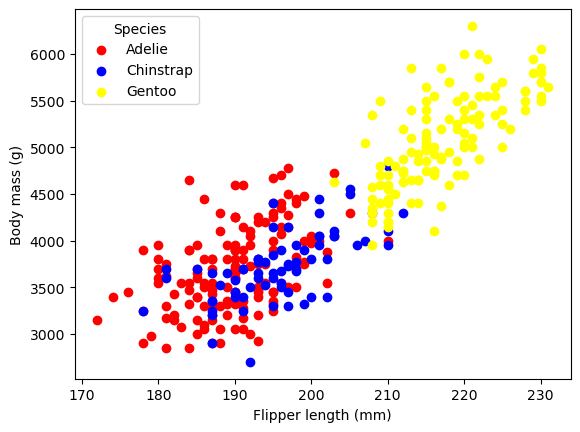

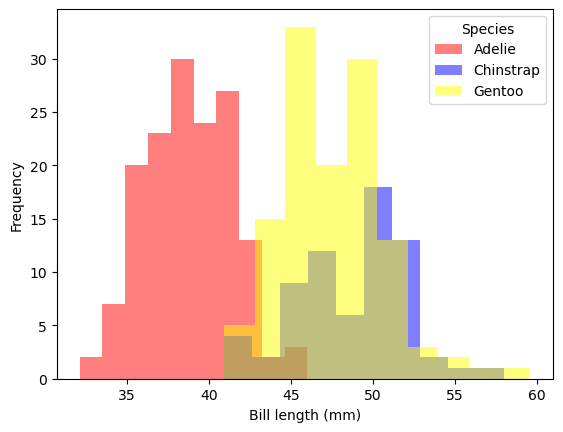

In [ ]:
# YOUR CODE HERE
seperatedPeng = [penguins[penguins["species"] == "Adelie"], penguins[penguins["species"] == "Chinstrap"], penguins[penguins["species"] == "Gentoo"]]
colours = np.array(["red", "blue", "yellow"])
species = np.array(["Adelie", "Chinstrap", "Gentoo"])
count = 0
for peng in seperatedPeng:
    xpoints = peng.get("flipper_length_mm")
    ypoints = peng.get("body_mass_g")

    plt.scatter(xpoints, ypoints, c=colours[count], label=species[count])
    count+=1
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.legend(title="Species")
plt.show()


count = 0
for peng in seperatedPeng:
    plt.hist(peng.get("bill_length_mm"), color=colours[count], label=species[count], alpha=0.5)
    count += 1
plt.xlabel("Bill length (mm)")
plt.ylabel("Frequency")
plt.legend(title="Species")
plt.show()
# Bill length and Flipper length appear most useful for telling species apart 
# as a large flipper length is indicitive of Gentoo penguins and 
# a shorter bill length is indicitive of Adelie penguins. 
# Together these 2 features could distinguish the species


## 3. The machine learning workflow, end to end (≈60 min)

### Step 1 — Problem framing
*Task:* given a penguin's bill length, bill depth and flipper length, predict its species.
*Type:* supervised learning, multi-class classification.
*Measure of success:* accuracy on previously unseen penguins.

### Step 2 — Data preparation
**TODO 3.1** Build the feature matrix `X` (a NumPy array with the three numerical features
named below) and label vector `y` (species names). Drop rows with missing values first.
Then split the data into 75 % training and 25 % test with `train_test_split`, using
`stratify=y` and `random_state=0`.

In [20]:
from sklearn.model_selection import train_test_split

FEATURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]
# YOUR CODE HERE
penguinsFull = penguins.dropna(subset=FEATURES + ["species"])
X = penguinsFull[FEATURES].to_numpy()
y = penguinsFull["species"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(X_train.shape, X_test.shape)

(256, 3) (86, 3)


### Step 3 — Algorithm selection: a baseline first
Before building anything clever, always ask *"what accuracy would a trivial model get?"*

**TODO 3.2** Implement a `MajorityClassifier` that ignores the features and always predicts
the most common class in the training data. Report its test accuracy.

In [22]:
class MajorityClassifier:
    def fit(self, X, y):
        # YOUR CODE HERE
        u, c = np.unique(y, return_counts=True)
        self.mostCommon = u[np.argmax(c)]
        return self

    def predict(self, X):
        # YOUR CODE HERE
        r, c = X.shape
        return np.full((r, 1), self.mostCommon)


def accuracy(y_true, y_pred):
    """Fraction of predictions that are correct."""
    # YOUR CODE HERE
    return sklearn.metrics.accuracy_score(y_true, y_pred)


baseline = MajorityClassifier().fit(X_train, y_train)
print("Baseline test accuracy:", round(accuracy(y_test, baseline.predict(X_test)), 3))

Baseline test accuracy: 0.442


### Step 4 — Model training: a nearest-centroid classifier from scratch
The **nearest-centroid** algorithm is one of the simplest learning algorithms:
* **fit:** for each class $c$, compute its *centroid* $\boldsymbol\mu_c$ — the mean feature vector of the training examples in that class.
* **predict:** assign a new example $\mathbf{x}$ to the class whose centroid is closest in Euclidean distance, $\hat y = \arg\min_c \lVert \mathbf{x} - \boldsymbol\mu_c \rVert_2$.

**TODO 3.3** Complete the class below. Try to write `predict` *without a Python loop over
examples* — broadcasting `X[:, None, :] - self.centroids_[None, :, :]` gives an array of
shape `(n_examples, n_classes, n_features)`.

In [25]:
class NearestCentroid:
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.centroids_ = np.stack([X[y==_].mean(0) for _ in self.classes_])
        return self

    def predict(self, X):
        differences = X[:, None, :] - self.centroids_[None, :, :]
        distances = np.linalg.norm(differences, axis=2)
        nearest = np.argmin(distances, axis=1)
        return self.classes_[nearest]




nc = NearestCentroid().fit(X_train, y_train)
print("Centroids:\n", pd.DataFrame(nc.centroids_, index=nc.classes_, columns=FEATURES))

Centroids:
            bill_length_mm  bill_depth_mm  flipper_length_mm
Adelie          39.006195      18.471681         190.345133
Chinstrap       48.994118      18.437255         196.098039
Gentoo          47.440217      14.911957         217.043478


### Step 5 — Model testing
**TODO 3.4** Report the training and test accuracy of your classifier, and check your
implementation against scikit-learn's `sklearn.neighbors.NearestCentroid`. They should agree.

In [56]:
from sklearn.neighbors import NearestCentroid as SkNearestCentroid

ownCode = NearestCentroid().fit(X_train, y_train)
skCode = sklearn.neighbors.NearestCentroid().fit(X_train, y_train)

ownPredictTrain = ownCode.predict(X_train)
ownPredictTest = ownCode.predict(X_test)
skPredict = skCode.predict(X_test)

print(f"The created model has accuracy {round(accuracy(y_train, ownPredictTrain), 4)} on the training data")
print(f"The created model has accuracy {round(accuracy(y_test, ownPredictTest), 4)} on the test data")
if np.array_equal(ownPredictTest, skPredict):
    print("The coded implementation provides the same predictions as sklearn's built-in function")
else:
    print("The coded implementation provides a different prediction to sklearn's built-in function")

The created model has accuracy 0.8945 on the training data
The created model has accuracy 0.9186 on the test data
The coded implementation provides the same predictions as sklearn's built-in function


### Step 6 — "Tuning": does feature scaling matter?
Our three features are on very different scales (bill depth ≈ 15–20 mm, flipper length ≈ 170–230 mm).
Distances are therefore dominated by flipper length.

**TODO 3.5** Standardise each feature using the **training set's** mean and standard deviation,
$x' = (x - \mu_{\text{train}})/\sigma_{\text{train}}$, apply the same transformation to the test
set, retrain, and compare the test accuracy. *(We will study why we must only use training
statistics in Practical 2.)*

In [58]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

new_X_train = (X_train - mean) / std
new_X_test = (X_test - mean) / std

retrained_model = NearestCentroid().fit(new_X_train, y_train)
new_predictTrain = retrained_model.predict(new_X_train)
new_predictTest = retrained_model.predict(new_X_test)

print(f"The retrained model has accuracy {round(accuracy(y_train, new_predictTrain), 4)} on the training data")
print(f"The retrained model has accuracy {round(accuracy(y_test, new_predictTest), 4)} on the test data")


The retrained model has accuracy 0.9727 on the training data
The retrained model has accuracy 0.9651 on the test data


### Step 7 — Inference
**TODO 3.6** A researcher measures a new penguin: bill length 47 mm, bill depth 15 mm,
flipper length 215 mm. What species does your (scaled) model predict?

In [55]:
new_penguin = np.array([[47.0, 15.0, 215.0]])
scaled_new_penguin = (new_penguin - mean) / std
print(f"The predicted penguin species is a {retrained_model.predict(scaled_new_penguin)[0]}")

The predicted penguin species is a Gentoo


In [61]:
print("Accuracy of certain models :\n", pd.DataFrame(np.array([
    [round(accuracy(y_train, baseline.predict(X_train)), 3), round(accuracy(y_test, baseline.predict(X_test)),4)],
    [round(accuracy(y_train, ownPredictTrain), 4), round(accuracy(y_test, ownPredictTest), 4)],
    [round(accuracy(y_train, new_predictTrain), 4), round(accuracy(y_test, new_predictTest), 4)]
    ]), index=np.array(["Majority baseline", "nearest-centroid", "scaled nearest-centroid"]), columns=np.array(["Accuracy on training data", "Accuracy on testing data"])))

Accuracy of certain models :
                          Accuracy on training data  Accuracy on testing data
Majority baseline                           0.4410                    0.4419
nearest-centroid                            0.8945                    0.9186
scaled nearest-centroid                     0.9727                    0.9651


## 4. Extension (if you have time)
* Which **pair** of the three features gives the best test accuracy on its own? Loop over all pairs.
* Visualise the decision regions of your nearest-centroid classifier for your best pair of
  features (hint: `np.meshgrid` + `plt.contourf`).
* Repeat the train/test split with 20 different `random_state` values. How much does the test
  accuracy vary? What does that tell you about trusting a single split?

In [ ]:
# YOUR CODE HERE

## Lab report checklist (Practical 1)
For this week's report, record:
1. The accuracy of the majority baseline and of your nearest-centroid classifier, before and after scaling (a small table).
2. One figure — e.g. the species scatter plot or your decision-region plot — with a caption.
3. A short explanation, in your own words, of what happens in each of the seven workflow steps *for this task*.
4. Why did scaling change (or not change) the result? Relate your answer to how the algorithm measures distance.